<a href="https://colab.research.google.com/github/Himanshu993527/AutoML-Model-Trainer/blob/main/Traning_Dataset_Weather_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Check TensorFlow and the GPU
import tensorflow as tf
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: []


In [ ]:
# Option B: direct upload (skip this cell if you used Option A)
from google.colab import files
files.upload()   # choose BOTH files in the dialog
!ls -lh /content/*.zip /content/*.csv

Saving weather-anomalies-1964-2013.csv to weather-anomalies-1964-2013.csv
ls: cannot access '/content/*.zip': No such file or directory
-rw-r--r-- 1 root root 265M Nov 21 10:13  /content/weather-anomalies-1964-2013.csv


In [ ]:
from google.colab import files
files.upload()

Saving WeatherAnomaly-DL.zip to WeatherAnomaly-DL.zip


{'WeatherAnomaly-DL.zip': b'PK\x03\x04\n\x00\x00\x00\x00\x00\xf6Iu]\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x12\x00\x1c\x00WeatherAnomaly-DL/UT\t\x00\x03?a\x01k?a\x01kux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\x00\x00\x00\x00PK\x03\x04\x14\x00\x00\x00\x08\x00{Iu]ob\x01\xb5B\x00\x00\x00C\x00\x00\x00"\x00\x1c\x00WeatherAnomaly-DL/requirements.txtUT\t\x00\x03Y`\x01kY`\x01kux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\x00\x00\x00\x00+I\xcd+\xce/J\xcb\xc9/\xb7\xb35\xd234\xe5*H\xccKI,\xe6\xca+\xcd-\xa8\xe4*N\xce\xcc\xce,\xd1\xcdIM,\xca\xe3\xcaM,)\xc8\xc9/\xc9\xc9L\xe2J\xcbI,\xce\xe6\xca\xcaO\x02q\x00PK\x03\x04\n\x00\x00\x00\x00\x00\xb9Iu]\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x1b\x00\x1c\x00WeatherAnomaly-DL/frontend/UT\t\x00\x03\xce`\x01k\x1da\x01kux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\x00\x00\x00\x00PK\x03\x04\x14\x00\x00\x00\x08\x00\xb9Iu]T\xec\x84\x18n\x00\x00\x00\x91\x00\x00\x00)\x00\x1c\x00WeatherAnomaly-DL/frontend/vite.config.jsUT\t\x00\x03\xce`\x01k\xce`\x01kux\x0b\x00\x01\x0

In [ ]:
!ls -lh /content/*.zip /content/*.csv

-rw-r--r-- 1 root root 265M Nov 21 10:13 /content/weather-anomalies-1964-2013.csv
-rw-r--r-- 1 root root  92K Nov 21 10:20 /content/WeatherAnomaly-DL.zip


In [ ]:
!cd /content && unzip -q -o "WeatherAnomaly-DL.zip"
!mv /content/weather-anomalies-1964-2013.csv /content/WeatherAnomaly-DL/data/
%cd /content/WeatherAnomaly-DL
!ls


/content/WeatherAnomaly-DL
api.py	 data	   README.md	   requirements.txt  train.py
backend  frontend  report_figures  standalone


In [ ]:
!python train.py --epochs 3 --max-train 100000

I0000 00:00:1795256553.323132    9023 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795256556.279478    9023 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Loading and cleaning data ...
rows: raw 3,196,832 -> clean 3,187,679; train 100,000  val 100,000  test 266,173
E0000 00:00:1795256563.662828    9023 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)

=== Training ANN (34,380 parameters) ===
Epoch 1/3
98/98 - 3s - 27ms/step - accuracy: 0.7179 - loss: 0.7803 - val_accuracy: 0.7901 - val_loss: 0.5237 - learning_rate: 0.0010
Epoch 2/3
98/98 - 1s - 10ms/step - accuracy: 0.8060 - loss: 0.5023 - val_accuracy: 0.8157 - val_loss: 0.4163 - learning_rate: 0.0010
Epoch 3/3
98/98 - 2s - 17ms/step - accuracy: 0.8213 - loss: 0.4384 - val_accuracy: 0.8185 - val_loss: 0.3916 - learning_rate: 0.0010
ANN: accuracy 0.8206  macro-F1 0.6880  time 5s

=== T

report_figures/model_comparison.png


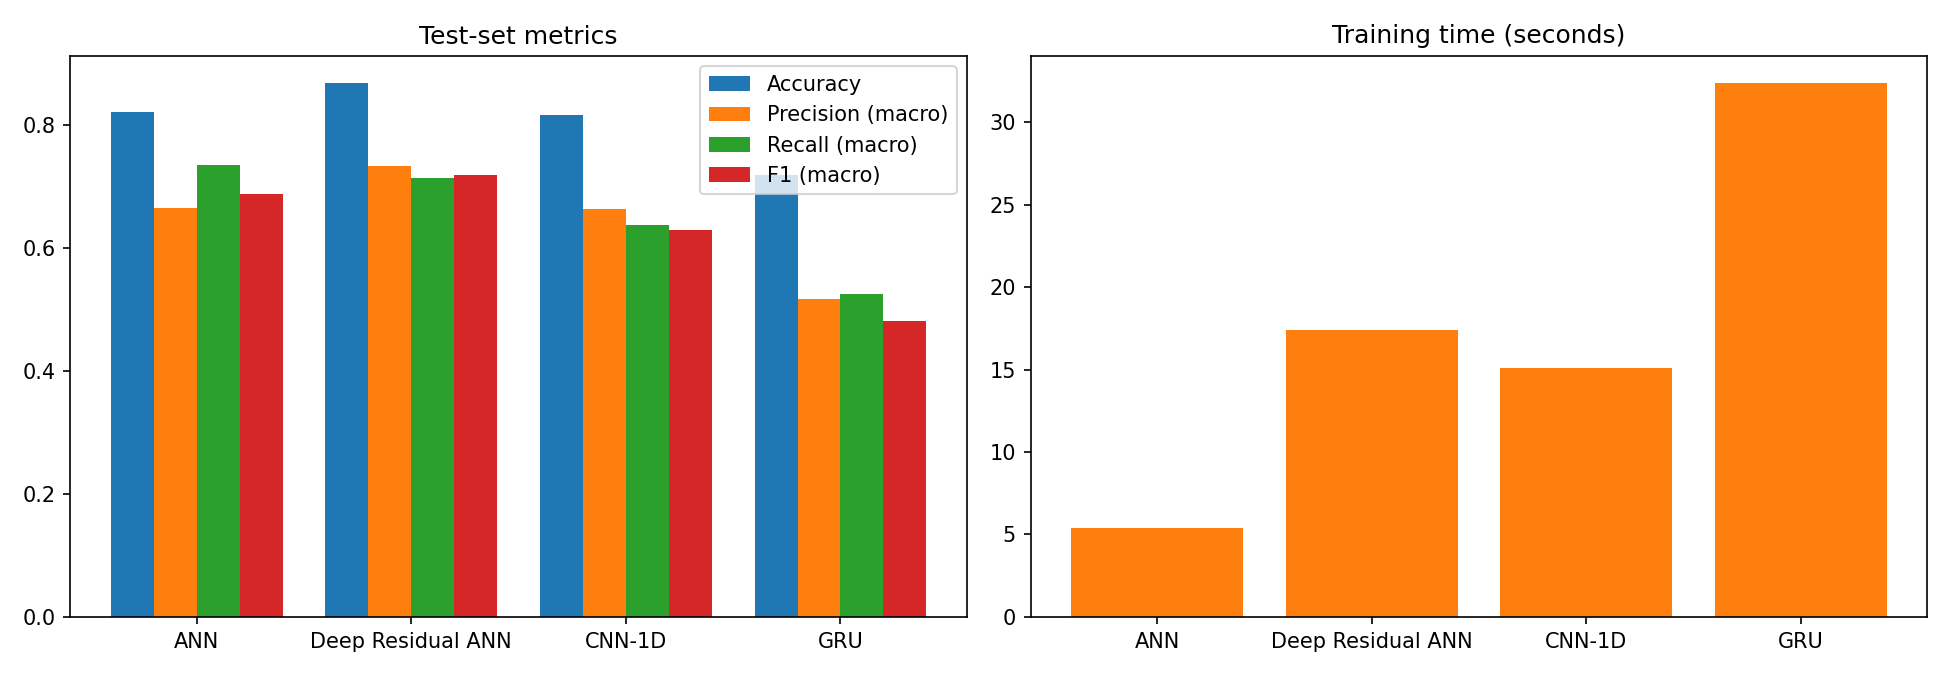

report_figures/training_curves.png


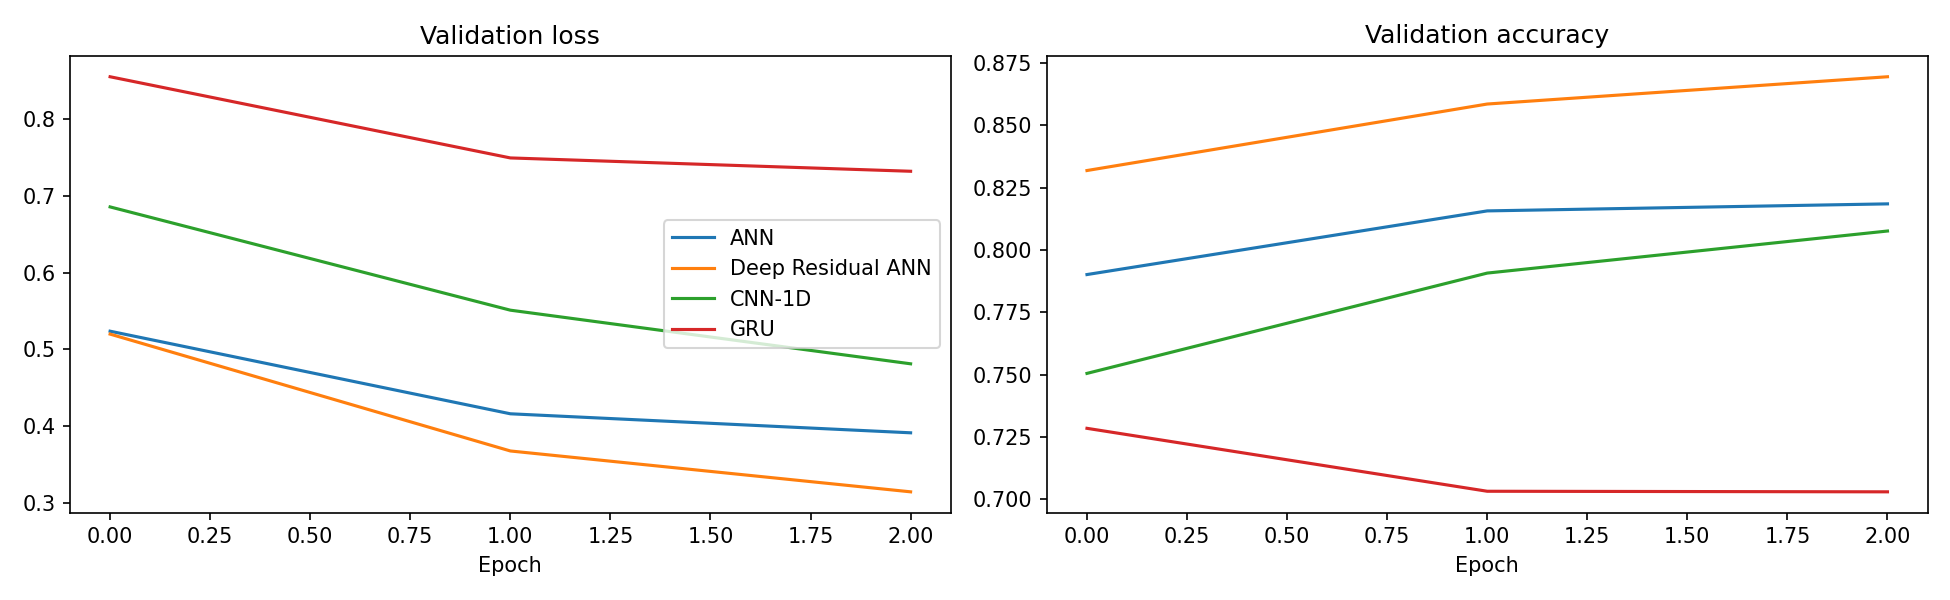

report_figures/confusion_ann.png


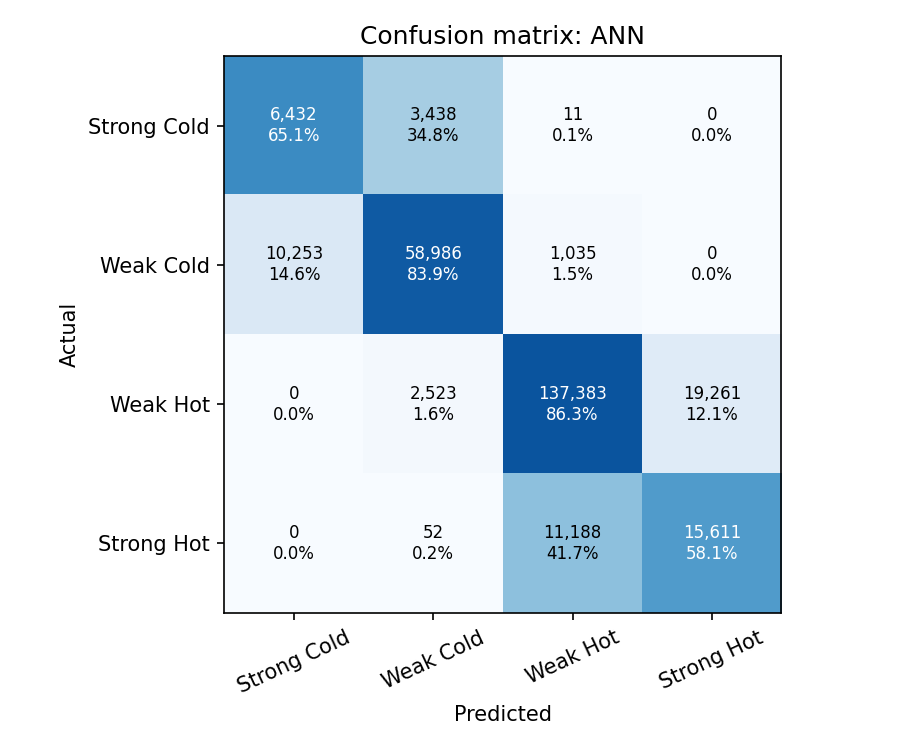

report_figures/confusion_cnn.png


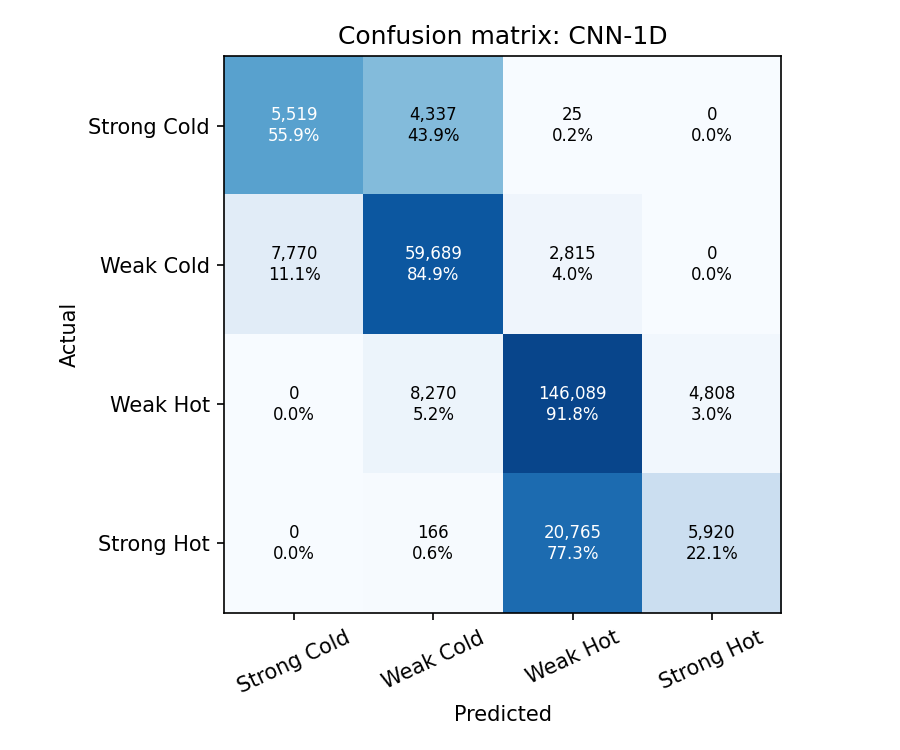

report_figures/confusion_dnn.png


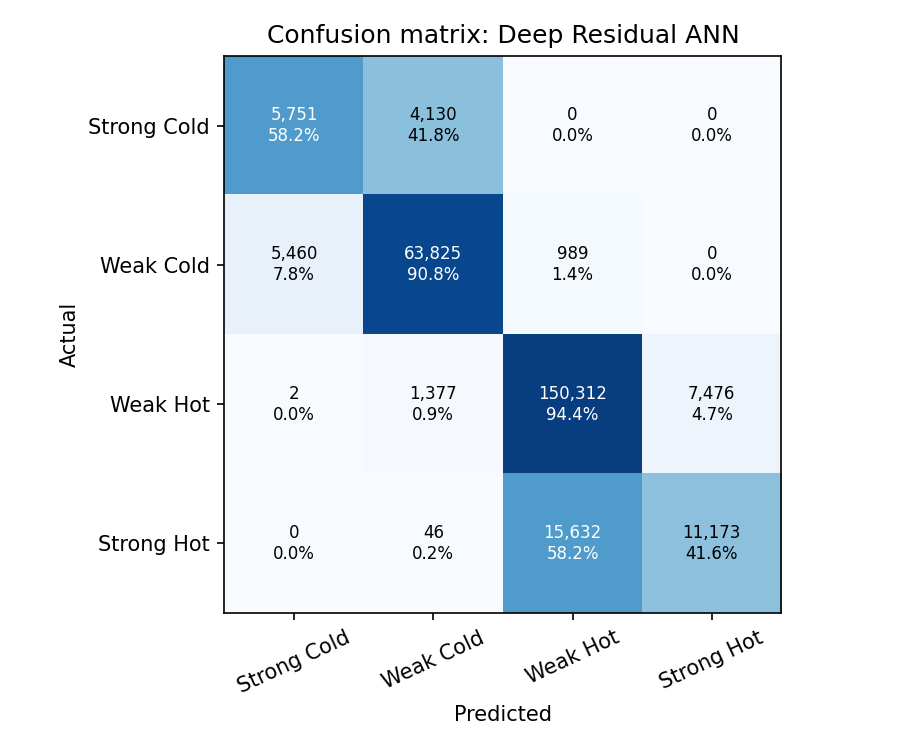

report_figures/confusion_gru.png


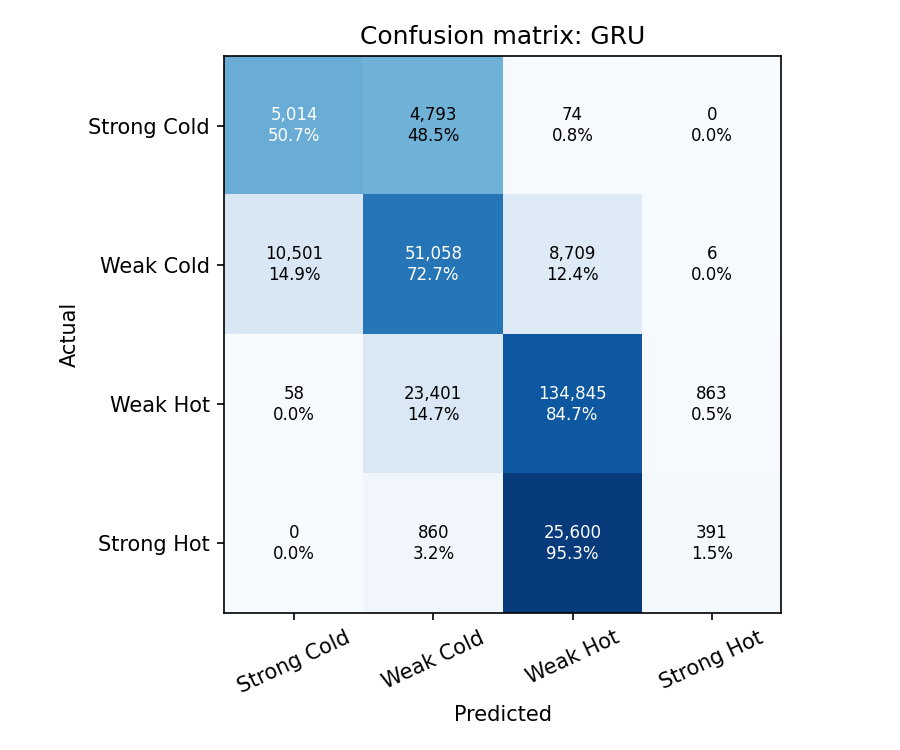

In [ ]:
# 6. Look at the figures
import glob
from IPython.display import Image, display
for f in ["report_figures/model_comparison.png", "report_figures/training_curves.png"] + sorted(glob.glob("report_figures/confusion_*.png")):
    print(f); display(Image(f))

In [ ]:
# 7. Download the results (results.json + figures + trained models)
!zip -qr results_package.zip frontend/public/results.json report_figures backend/artifacts
from google.colab import files
files.download("results_package.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>